# Inspect Generated OT Dataset

This notebook loads a generated dataset (from `run_datagenerator.py` output) and visualizes the first few samples to verify correctness.

In [6]:
CUDA_VISIBLE_DEVICES=1
import os
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset, load_from_disk
from scipy import sparse
import torch

# %matplotlib inline

In [7]:
# CONFIGURATION
# Path to the dataset directory (local path or HF hub ID)
# Adjust this to point to your output_dir from run_datagenerator.py
# DATASET_PATH = "./ot_dataset" 
DATASET_PATH = "ivanjaenm/otdata_100K_rowwise_costtype_sqeuclidean_variable_bins10"
SPLIT = "train" 
NUM_PAIRS = 5 # Number of distribution pairs to visualize

In [8]:
# Load dataset
print(f"Loading dataset from: {DATASET_PATH}")
try:
    # Try loading from local disk first
    if os.path.exists(DATASET_PATH):
        dataset = load_from_disk(DATASET_PATH)
    else:
        # Fallback to HF hub loading
        # cache_dir can be specified if needed, defaulting to HF default
        dataset = load_dataset(DATASET_PATH)
except Exception as e:
    print(f"Error loading dataset: {e}")
    raise e

ds = dataset[SPLIT]
print(f"Features: {ds.features}")
print(f"Num rows: {len(ds)}")

Loading dataset from: ivanjaenm/otdata_100K_rowwise_costtype_sqeuclidean_variable_bins10
Features: {'input_cost_type': List(Value('float64')), 'input_cost_matrix': List(List(Value('float64'))), 'input_idx': List(Value('float64')), 'input_total': List(Value('float64')), 'target_otplan_solve_sparse': List(Value('float64'))}
Num rows: 800000


In [9]:
# Column Constants
OT_INPUT_TOTAL         = "input_total"
OT_INPUT_COST_ONEHOT   = "input_cost_type"
OT_INPUT_COST_MATRIX   = "input_cost_matrix"
OT_TARGET_PLAN_MATRIX_SPARSE  = "target_otplan_solve_sparse"

def plot_pair_batch(batch, n_bins, idx):
    # batch is a dict of lists, length n_bins
    # We assume all rows in the batch belong to the same pair (same inputs)
    
    fig, ax = plt.subplots(1, 4, figsize=(20, 4))
    
    # Extract from input_total of the first row
    input_total = np.array(batch[OT_INPUT_TOTAL][0])
    
    source = input_total[:n_bins]
    target = input_total[n_bins:2*n_bins]
    
    # 1. Source Distribution
    ax[0].bar(range(len(source)), source, color='skyblue', edgecolor='black')
    ax[0].set_title(f"Pair {idx}: Source")
    ax[0].set_ylim(0, max(source.max(), target.max())*1.1)
    
    # 2. Target Distribution
    ax[1].bar(range(len(target)), target, color='skyblue', edgecolor='black')
    ax[1].set_title(f"Pair {idx}: Target")
    ax[1].set_ylim(0, max(source.max(), target.max())*1.1)
    
    # 3. Cost Matrix
    C = None
    # Check first row for cost matrix
    if OT_INPUT_COST_MATRIX in batch and batch[OT_INPUT_COST_MATRIX][0] is not None:
        C = np.array(batch[OT_INPUT_COST_MATRIX][0])
        im = ax[2].imshow(C, cmap='viridis', origin='lower')
        ax[2].set_title("Cost Matrix")
        plt.colorbar(im, ax=ax[2])
    else:
        ax[2].text(0.5, 0.5, "Fixed/Semivariable Cost\n(Not in sample)", ha='center')
        ax[2].set_title("Cost Matrix")

    # 4. OT Plan (Target) - RECONSTRUCTION
    ot_target_sparse_rows = batch[OT_TARGET_PLAN_MATRIX_SPARSE]
    # Reconstruct sparse matrix from rows
    # Each row i (0 to n_bins-1) is a list [c, v, c, v, ...]
    gt_rows = []
    gt_cols = []
    gt_data = []
    for i, row_data in enumerate(ot_target_sparse_rows):
        # Handle potential tensor/list differences
        if hasattr(row_data, 'tolist'):
             row_data = row_data.tolist()
        # row_data is [col, val, col, val, ...]
        for k in range(0, len(row_data), 2):
             c = int(row_data[k])
             v = float(row_data[k+1])
             gt_rows.append(i)
             gt_cols.append(c)
             gt_data.append(v)
    
    ot_target_sparse = sparse.coo_matrix((gt_data, (gt_rows, gt_cols)), shape=(n_bins, n_bins))
    ot_target_dense  = ot_target_sparse.toarray()
                
    im4 = ax[3].imshow(ot_target_dense, cmap='Purples', origin='lower')
    ax[3].set_title(f"OT Plan (Sum={ot_target_dense.sum():.4f})")
    plt.colorbar(im4, ax=ax[3])

    plt.tight_layout()
    plt.show()

Detected n_bins: 10


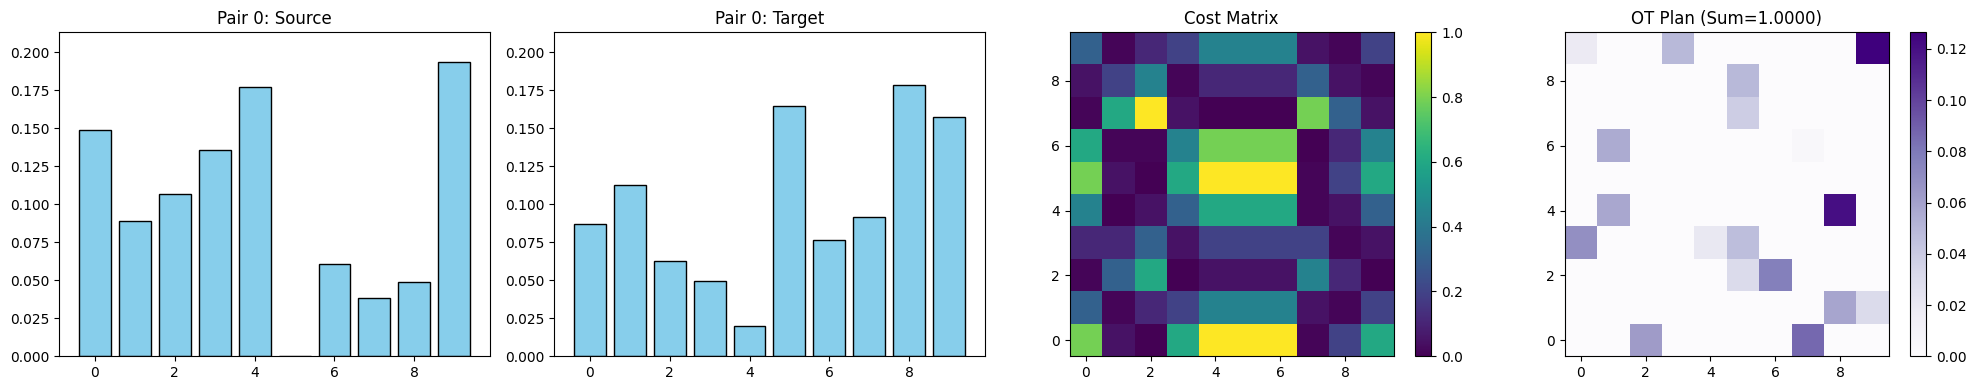

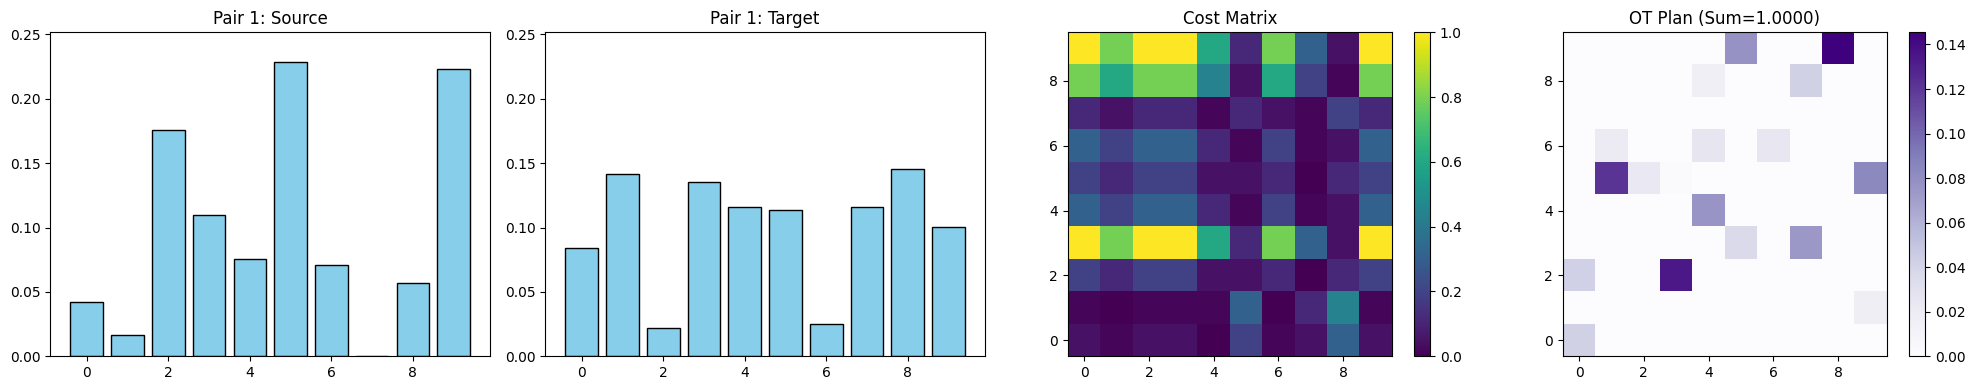

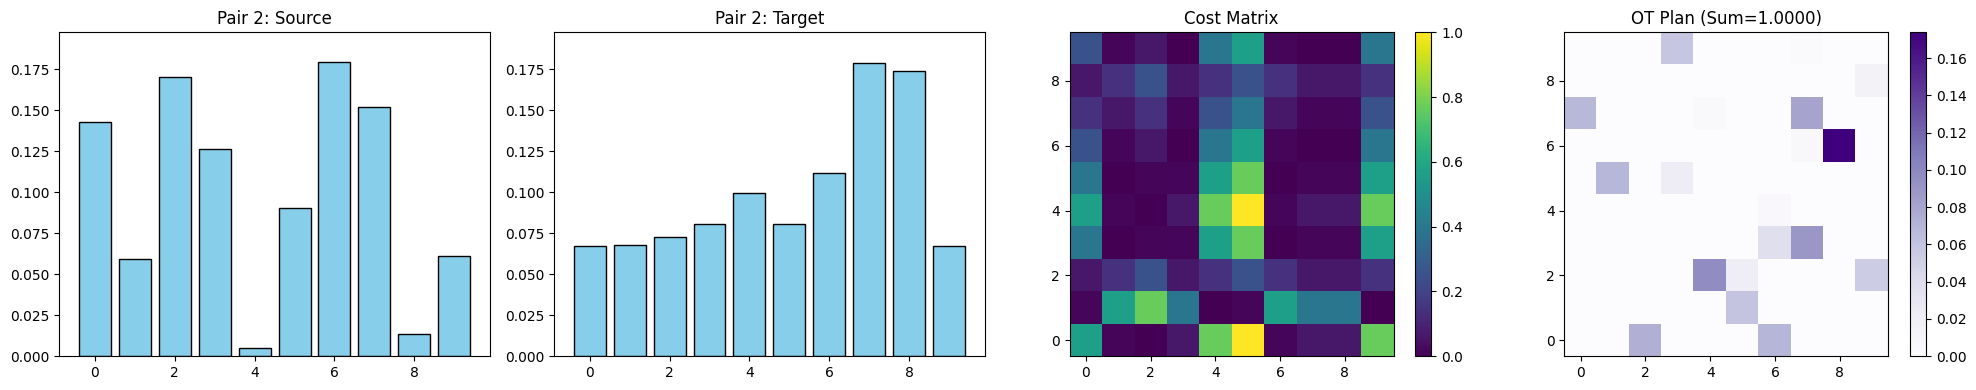

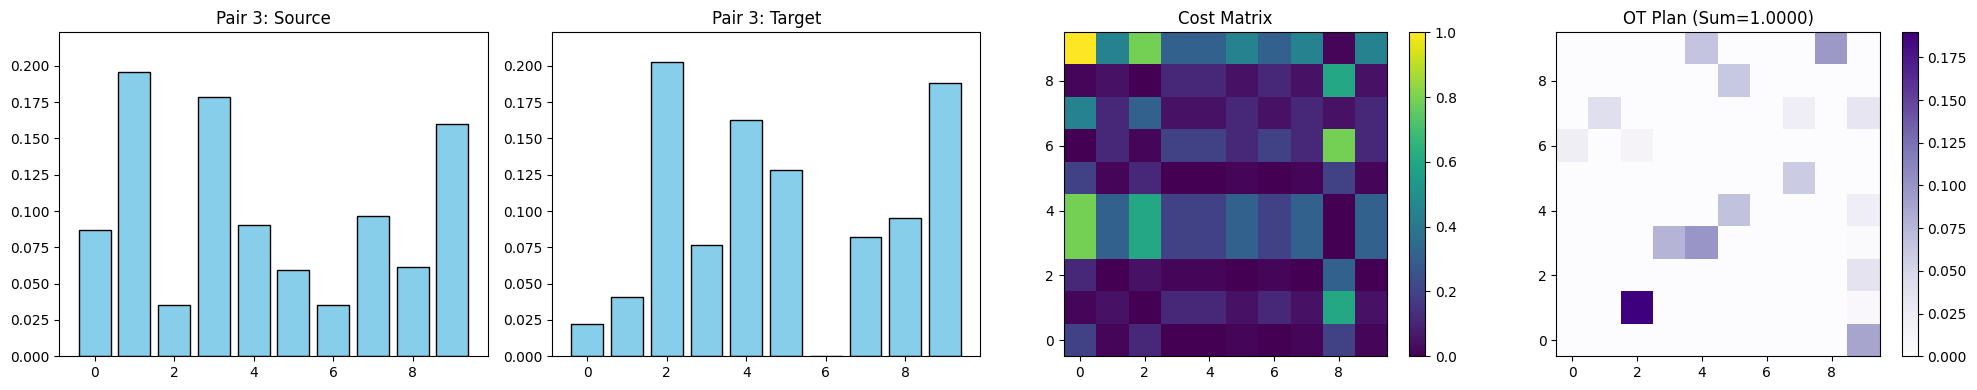

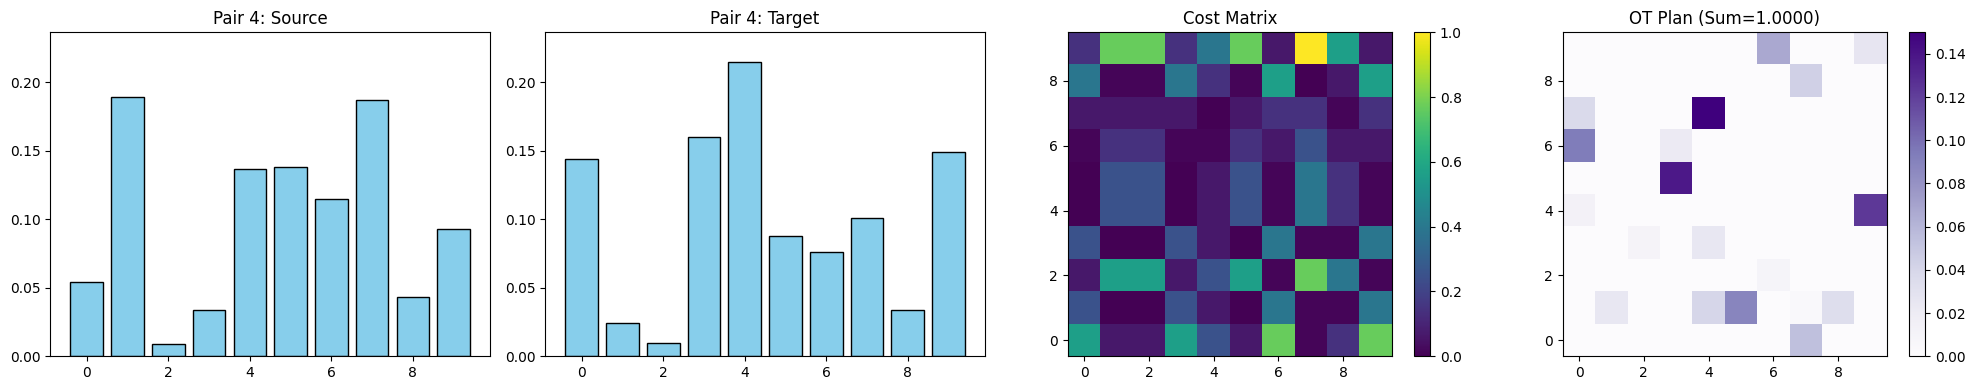

In [10]:
# Determine n_bins from first sample
sample0 = ds[0]
input_total = np.array(sample0[OT_INPUT_TOTAL])
if len(input_total) % 2 != 0:
    n_bins = (len(input_total) - 1) // 2
else:
    n_bins = len(input_total) // 2
n_bins = int(n_bins)
print(f"Detected n_bins: {n_bins}")

# Visualize first few PAIRS
# We slice the dataset in chunks of n_bins
for i in range(NUM_PAIRS):
    start = i * n_bins
    end = start + n_bins
    
    if end > len(ds):
        print("End of dataset reached.")
        break
        
    # Get batch (dict of lists)
    batch = ds[start:end]
    plot_pair_batch(batch, n_bins, i)